# **Board Detector**

This notebook finds the dartboard in a video and draws two ellipses:

* **Outer ellipse (green)** – the **white wire circle** that the numbers are made of. It is a thin bright line on the black board, so it is easy to find on any background.
* **Inner ellipse (red)** – the outer edge of the **double ring**. Everything inside this ellipse scores points.

The board is round, but because the camera looks at it from an angle it appears as an **ellipse** in the image.
Both circles lie in the same flat plane, so they are tilted by exactly the same amount. We therefore measure the tilt on the outer ellipse and **reuse it for the inner ellipse**.

### Pipeline

| Step | What it does | Course content |
|---|---|---|
| 1. Median frame | Combine many frames into one clean image without people or noise | L01b Noise (averaging) |
| 2. Board centre | Every sector edge points at the centre, so edge pixels "vote" for it | L04 Edges (gradient, Canny) + idea of the Hough transform |
| 3. White wire | Polar image + top-hat (image minus opening) keeps only thin bright lines | L02 Erosion/dilation, L01b/L03 resampling |
| 4. Outer ellipse | Fit an ellipse that ignores wrong points (RANSAC), then snap it to the wire | Beyond the slides (RANSAC) |
| 5. Inner ellipse | Find the double ring edge in each direction, then fit with the tilt fixed | L04 Edges, L05 HSV colour space |
| 6. Check | Run on all videos and test against what we know about the board | Verification |

Each step is a separate function with an example image below it. All steps run at the full 1920 × 1080 resolution, except the centre search.

In [1]:
from pathlib import Path
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 72   # keeps the notebook file small

## **Settings and helper functions**

In [2]:
VIDEO_DIR = Path("../data/videos")
FIGURE_DIR = Path("../reports/figures")

N_ANGLES = 720     # number of directions around the board (0.5 degree steps)

videos = sorted(VIDEO_DIR.glob("*.mp4"))
for v in videos:
    print(v.name)

black_background_LightChange.mp4
black_background_noHuman.mp4
black_background_yesHuman.mp4
white_background_LightChange.mp4
white_background_noHuman.mp4
white_background_yesHuman.mp4
wood_background_Angle.mp4
wood_background_LightChange.mp4
wood_background_noHuman.mp4
wood_background_yesHuman.mp4


In [3]:
def show(images, titles, size=6):
    # Shows a list of images next to each other (BGR colour images are converted to RGB)
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.6))
    axs = np.atleast_1d(axs)

    for ax, image, title in zip(axs, images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def crop_around(image, centre, half_size):
    # Cuts out a square around a point (pads with black if the square leaves the image)
    x, y = int(centre[0]), int(centre[1])
    padded = cv2.copyMakeBorder(image, half_size, half_size, half_size, half_size, cv2.BORDER_CONSTANT)
    return padded[y:y + 2 * half_size, x:x + 2 * half_size]


def direction_angles():
    return 2 * np.pi * np.arange(N_ANGLES) / N_ANGLES

## **Step 1: Combine the video into one clean frame**

The camera and the board do not move during calibration. If we take every 10th frame and compute the **median of each pixel over time**, then:

* a person walking past disappears, because they only cover a pixel for a short time,
* sensor noise is reduced, which keeps the thin white wire sharp.

We then only need to detect the board once, on this clean image.

In [4]:
def median_frame(video_path, step=10):
    cap = cv2.VideoCapture(str(video_path))
    frames, index = [], 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if index % step == 0:
            frames.append(frame)
        index += 1

    cap.release()
    return np.median(np.stack(frames), axis=0).astype(np.uint8), frames

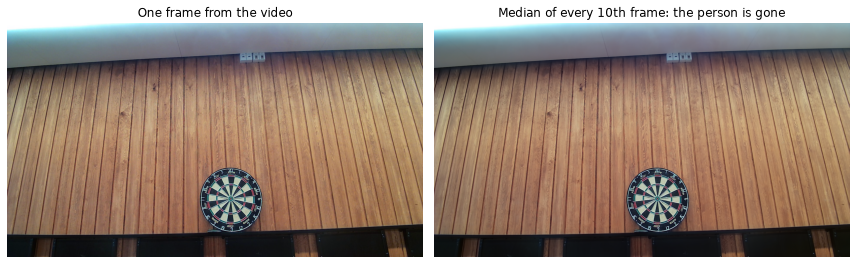

In [5]:
example_video = VIDEO_DIR / "wood_background_yesHuman.mp4"
clean, frames = median_frame(example_video)
show([frames[8], clean], ["One frame from the video", "Median of every 10th frame: the person is gone"])

## **Step 2: Find the board centre by edge voting**

The 20 sector boundaries of a dartboard are straight lines that all go through the **bullseye**.
That gives a simple way to find the centre, similar to the Hough transform (L04):

1. Find edge pixels with **Canny**.
2. At each edge pixel, the **Sobel gradient** points across the edge, so the edge itself runs perpendicular to the gradient.
3. Every edge pixel draws a short line along its edge direction into an empty "vote" image.
4. Lines from all sector edges cross at the bullseye, so that pixel collects the most votes.

Background lines (e.g. wood planks) are mostly parallel, so they do not build up a single strong peak.
This step runs at half resolution, because the centre is only a starting point for the next steps.

In [6]:
def find_centre(image):
    small = cv2.resize(image, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (0, 0), 1.5)

    edges = cv2.Canny(gray, 50, 150)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)

    ys, xs = np.nonzero(edges)
    magnitude = np.hypot(gx[ys, xs], gy[ys, xs]) + 1e-6

    # Unit vector along the edge (perpendicular to the gradient)
    dx = -gy[ys, xs] / magnitude
    dy = gx[ys, xs] / magnitude

    # Every edge pixel votes for all pixels on a short line through it
    votes = np.zeros(gray.shape, np.float32)
    line_length = gray.shape[0] // 8

    for t in range(-line_length, line_length + 1):
        px = np.round(xs + t * dx).astype(int)
        py = np.round(ys + t * dy).astype(int)
        inside = (px >= 0) & (px < gray.shape[1]) & (py >= 0) & (py < gray.shape[0])
        np.add.at(votes, (py[inside], px[inside]), 1)

    votes = cv2.GaussianBlur(votes, (0, 0), 3)
    _, _, _, peak = cv2.minMaxLoc(votes)

    # Back to full resolution coordinates
    return (2 * peak[0], 2 * peak[1]), edges, votes

Board centre (x, y): (1032, 810)


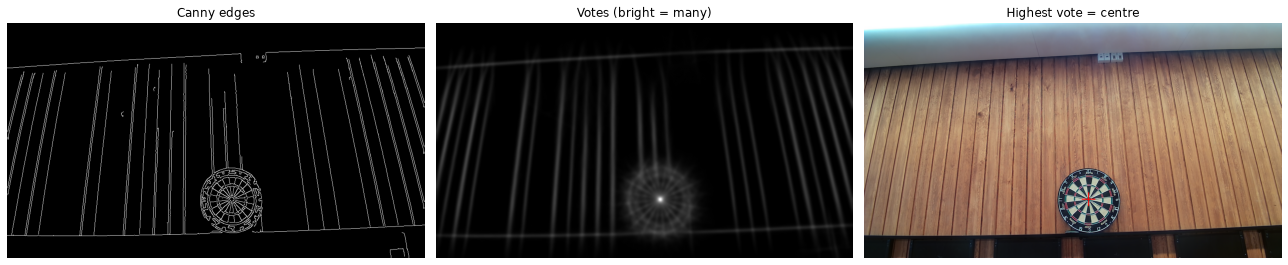

In [7]:
centre, edges, votes = find_centre(clean)
print("Board centre (x, y):", centre)

marked = clean.copy()
cv2.drawMarker(marked, centre, (0, 0, 255), cv2.MARKER_CROSS, 60, 3)

show([edges, votes / votes.max(), marked], ["Canny edges", "Votes (bright = many)", "Highest vote = centre"])

## **Step 3: Find the white wire**

**Polar image.** We re-sample the image along rays that start at the centre.
In the new image, each **row is one direction** and each **column is the distance from the centre**.
Circles around the centre become (almost) vertical lines, and each direction becomes a simple 1D search.

**Top-hat.** The wire is a thin bright line on black. A morphological *opening* (erosion followed by dilation, L02) removes bright details thinner than the structuring element.
So **image minus opening** (the "top-hat") keeps exactly those thin bright lines.
The structuring element is 11 px long along the radius only. The circular wire crosses the radius, so it is thin in that direction and is kept. The wall gives almost nothing, because it has no thin bright lines.

**Search area.** The black number ring is the darkest wide ring on the board, so it gives a rough board size `r_dark`. The wire must be just outside its middle.
In each direction we take the **outermost** strong response, because the digits sit further in than the wire.

In [8]:
def polar_image(gray, centre, max_radius):
    # Row i = direction i * 360 / N_ANGLES degrees, column j = distance j from the centre
    angles = direction_angles()
    radii = np.arange(max_radius, dtype=np.float32)[None, :]

    map_x = centre[0] + radii * np.cos(angles)[:, None]
    map_y = centre[1] + radii * np.sin(angles)[:, None]

    return cv2.remap(gray, map_x.astype(np.float32), map_y.astype(np.float32), cv2.INTER_LINEAR).astype(np.float32)


def thin_bright_lines(polar):
    # Top-hat along the radius: image minus opening
    opened = cv2.morphologyEx(polar, cv2.MORPH_OPEN, np.ones((1, 11), np.uint8))
    return polar - opened


def darkest_ring(polar):
    # Opening also removes the digits, so the median brightness shows the black ring clearly
    without_digits = cv2.morphologyEx(polar, cv2.MORPH_OPEN, np.ones((13, 13), np.uint8))
    profile = np.convolve(np.median(without_digits, axis=0), np.ones(15) / 15, mode="same")
    return 30 + int(np.argmin(profile[30:-30])), profile


def polar_to_points(centre, radius_per_angle):
    # Converts one radius per direction back to (x, y) image points
    angles = direction_angles()
    x = centre[0] + radius_per_angle * np.cos(angles)
    y = centre[1] + radius_per_angle * np.sin(angles)
    return np.column_stack([x, y]).astype(np.float32)


def find_wire_points(top_hat, centre, r_dark):
    r_max = min(int(1.5 * r_dark), top_hat.shape[1] - 1)
    band = top_hat[:, r_dark:r_max]

    # Last (outermost) position that is at least half as strong as the strongest one
    strong = band >= 0.5 * band.max(axis=1, keepdims=True)
    outermost = band.shape[1] - 1 - np.argmax(strong[:, ::-1], axis=1)

    return polar_to_points(centre, r_dark + outermost)

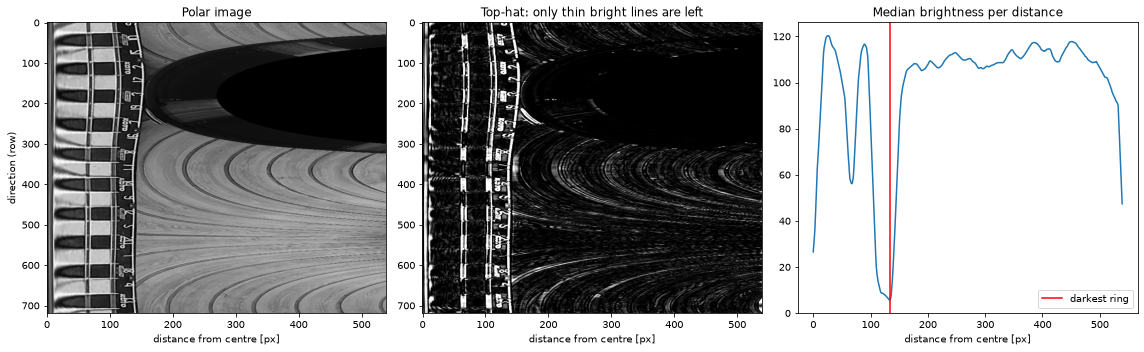

In [9]:
gray = cv2.cvtColor(clean, cv2.COLOR_BGR2GRAY)
polar = polar_image(gray, centre, gray.shape[0] // 2)
top_hat = thin_bright_lines(polar)
r_dark, profile = darkest_ring(polar)
wire_points = find_wire_points(top_hat, centre, r_dark)

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].imshow(polar, cmap="gray", aspect="auto")
axs[0].set_title("Polar image")
axs[0].set_xlabel("distance from centre [px]")
axs[0].set_ylabel("direction (row)")
axs[1].imshow(np.clip(top_hat, 0, 60), cmap="gray", aspect="auto")
axs[1].set_title("Top-hat: only thin bright lines are left")
axs[1].set_xlabel("distance from centre [px]")
axs[2].plot(profile)
axs[2].axvline(r_dark, color="r", label="darkest ring")
axs[2].set_title("Median brightness per distance")
axs[2].set_xlabel("distance from centre [px]")
axs[2].legend()
plt.tight_layout()
plt.show()

## **Step 4: Outer ellipse**

Some wire points are wrong, e.g. where the wire is hidden behind the shelf or the books.
A normal fit (`cv2.fitEllipse`) uses every point, so a few wrong points bend the whole ellipse.

**RANSAC** is built for this:

1. Pick 5 random points and fit an ellipse through them.
2. Count how many of all points lie within 2 px of it.
3. Repeat many times and keep the ellipse that most points agree with.
4. Do a final fit on only those points.

RANSAC is not in the slides, but it is a standard method and is covered in the course book (Szeliski).

**Snap to the wire.** Now that we know roughly where the ellipse is, we look only 8 px to each side of it and take the strongest wire response in each direction. Repeating this three times locks the ellipse onto the wire.

In [10]:
def ellipse_error_px(points, ellipse):
    # Rough distance in pixels from each point to the ellipse
    (cx, cy), (width, height), angle = ellipse
    t = np.radians(angle)
    dx, dy = points[:, 0] - cx, points[:, 1] - cy

    # Rotate the points into the ellipse's own coordinate system; on the ellipse u^2 + v^2 = 1
    u = (dx * np.cos(t) + dy * np.sin(t)) / (width / 2)
    v = (-dx * np.sin(t) + dy * np.cos(t)) / (height / 2)

    return np.abs(np.sqrt(u**2 + v**2) - 1) * (width + height) / 4


def fit_ellipse_ransac(points, tolerance=2.0, tries=800):
    rng = np.random.default_rng(0)
    best_ellipse, best_count = None, 0

    for _ in range(tries):
        sample = points[rng.choice(len(points), 5, replace=False)]
        ellipse = cv2.fitEllipse(sample)
        axes = ellipse[1]

        # Skip degenerate ellipses
        if not np.all(np.isfinite(axes)) or min(axes) <= 0 or max(axes) > 2000:
            continue

        count = np.sum(ellipse_error_px(points, ellipse) < tolerance)
        if count > best_count:
            best_ellipse, best_count = ellipse, count

    inliers = points[ellipse_error_px(points, best_ellipse) < tolerance]
    return cv2.fitEllipse(inliers), inliers

In [11]:
def ellipse_radius_per_angle(ellipse, centre):
    # Distance from `centre` to the ellipse, for each direction
    (cx, cy), (width, height), angle = ellipse
    t = np.linspace(0, 2 * np.pi, 4000, endpoint=False)
    a = np.radians(angle)
    x = cx + width / 2 * np.cos(t) * np.cos(a) - height / 2 * np.sin(t) * np.sin(a)
    y = cy + width / 2 * np.cos(t) * np.sin(a) + height / 2 * np.sin(t) * np.cos(a)

    point_angles = np.arctan2(y - centre[1], x - centre[0]) % (2 * np.pi)
    point_radii = np.hypot(x - centre[0], y - centre[1])
    order = np.argsort(point_angles)

    return np.interp(direction_angles(), point_angles[order], point_radii[order], period=2 * np.pi)


def snap_to_wire(ellipse, top_hat, centre, search=8):
    expected = ellipse_radius_per_angle(ellipse, centre)
    radii = np.zeros(N_ANGLES)

    for i in range(N_ANGLES):
        start = max(int(expected[i]) - search, 0)
        segment = top_hat[i, start:int(expected[i]) + search + 1]
        segment = np.convolve(segment, [0.25, 0.5, 0.25], mode="same")
        radii[i] = start + np.argmax(segment)

    return polar_to_points(centre, radii)


def find_outer_ellipse(gray, centre):
    polar = polar_image(gray, centre, gray.shape[0] // 2)
    top_hat = thin_bright_lines(polar)
    r_dark, _ = darkest_ring(polar)

    ellipse, _ = fit_ellipse_ransac(find_wire_points(top_hat, centre, r_dark))
    for _ in range(3):
        points = snap_to_wire(ellipse, top_hat, centre)
        ellipse, inliers = fit_ellipse_ransac(points)

    return ellipse, points, inliers

649 of 720 directions agree with the ellipse
Outer ellipse: centre [1033.9  817.4] axes [277.6 290. ] angle 163.1


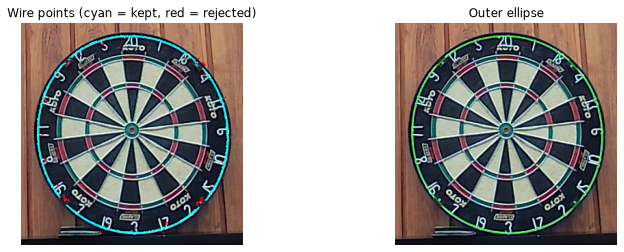

In [12]:
outer_ellipse, outer_points, outer_inliers = find_outer_ellipse(gray, centre)
print(f"{len(outer_inliers)} of {N_ANGLES} directions agree with the ellipse")
print("Outer ellipse: centre", np.round(outer_ellipse[0], 1), "axes", np.round(outer_ellipse[1], 1), "angle", round(outer_ellipse[2], 1))

half_size = int(0.56 * max(outer_ellipse[1]))
result = clean.copy()
for x, y in outer_points:
    cv2.circle(result, (int(x), int(y)), 1, (0, 0, 255), -1)
for x, y in outer_inliers:
    cv2.circle(result, (int(x), int(y)), 1, (255, 255, 0), -1)
points_view = crop_around(result, outer_ellipse[0], half_size)

result = clean.copy()
cv2.ellipse(result, outer_ellipse, (0, 255, 0), 1, cv2.LINE_AA)
ellipse_view = crop_around(result, outer_ellipse[0], half_size)

show([points_view, ellipse_view], ["Wire points (cyan = kept, red = rejected)", "Outer ellipse"])

## **Step 5: Inner ellipse (outer edge of the double ring)**

**Unroll the board.** We sample the image along ellipses with the same shape as the outer ellipse, scaled by a factor from 0.3 to 1.0.
Each column is one scale, and each row is one direction, so the outer ellipse becomes a straight line at 1.0.
The tilt of the camera is removed, and the only thing left to find is **where the double ring is**.

**Rough position.** Between the double ring and the wire the board is almost black, while the double ring is bright. We use the **V channel** of HSV (L05) because red and green rings are both bright in V, even though they look different in gray.
The median of each column ignores digits and logos, since they only appear in some directions. Walking inward from the wire, the first column that gets clearly brighter is the double ring.

**Exact position in each direction.** Close to that position we find the strongest **bright → dark step** (Sobel, L04) in each row.

**Fit with the tilt fixed.** Now we use the fact that both circles lie in the same plane. We transform the points so the outer ellipse becomes a unit circle, and in those coordinates the double ring is a circle too.
So we only fit a **centre and a radius**. RANSAC removes the wrong points here as well.

The centre is free because of perspective: a circle's centre in the image does not stay at the same point when the circle gets smaller. The inner ellipse has the same shape as the outer one but may sit a few pixels away from it.

In [13]:
def unroll_board(image, outer_ellipse, bullseye, scales):
    (ex, ey), (width, height), angle = outer_ellipse
    a = np.radians(angle)
    s, t = np.meshgrid(scales, direction_angles())

    # The ellipse centre moves from the bullseye (s = 0) to the outer ellipse centre (s = 1)
    cx = bullseye[0] + s**2 * (ex - bullseye[0])
    cy = bullseye[1] + s**2 * (ey - bullseye[1])

    map_x = (cx + s * (width / 2 * np.cos(t) * np.cos(a) - height / 2 * np.sin(t) * np.sin(a))).astype(np.float32)
    map_y = (cy + s * (width / 2 * np.cos(t) * np.sin(a) + height / 2 * np.sin(t) * np.cos(a))).astype(np.float32)

    return cv2.remap(image, map_x, map_y, cv2.INTER_LINEAR), map_x, map_y

In [14]:
def rough_ring_edge(brightness, scales):
    def column(scale):
        return int(np.searchsorted(scales, scale))

    black = np.median(brightness[column(0.85):column(0.95)])
    cream = np.median(brightness[column(0.45):column(0.65)])
    threshold = black + 0.15 * (cream - black)

    j = column(0.93)
    while brightness[j] < threshold:
        j -= 1

    return j, threshold


def find_ring_points(value, map_x, map_y, rough_edge, scales):
    half_width = int(0.03 / (scales[1] - scales[0]))
    start, stop = rough_edge - half_width, rough_edge + half_width

    # Most negative step along the scale axis = bright -> dark going outwards
    step = cv2.Sobel(cv2.blur(value, (3, 1)), cv2.CV_32F, 1, 0, ksize=5)
    columns = start + np.argmin(step[:, start:stop], axis=1)

    rows = np.arange(N_ANGLES)
    return np.column_stack([map_x[rows, columns], map_y[rows, columns]])

In [15]:
def to_unit_circle(points, ellipse):
    # Moves, rotates and stretches the points so that `ellipse` becomes the unit circle
    (ex, ey), (width, height), angle = ellipse
    a = np.radians(angle)
    dx, dy = points[:, 0] - ex, points[:, 1] - ey
    u = (dx * np.cos(a) + dy * np.sin(a)) / (width / 2)
    v = (-dx * np.sin(a) + dy * np.cos(a)) / (height / 2)
    return u, v


def fit_circle(u, v):
    # Least squares circle: u^2 + v^2 = 2*a*u + 2*b*v + c
    A = np.column_stack([2 * u, 2 * v, np.ones(len(u))])
    a, b, c = np.linalg.lstsq(A, u**2 + v**2, rcond=None)[0]
    return a, b, np.sqrt(c + a**2 + b**2)


def fit_same_shape_ellipse(points, outer_ellipse, tolerance_px=1.5, tries=500):
    (ex, ey), (width, height), angle = outer_ellipse
    u, v = to_unit_circle(points, outer_ellipse)
    tolerance = tolerance_px / ((width + height) / 4)
    rng = np.random.default_rng(0)
    best_circle, best_count = None, 0

    # RANSAC with 3 points, since a circle needs 3 points
    for _ in range(tries):
        i = rng.choice(len(u), 3, replace=False)
        a, b, radius = fit_circle(u[i], v[i])
        if not np.isfinite(radius) or radius >= 1:
            continue
        count = np.sum(np.abs(np.hypot(u - a, v - b) - radius) < tolerance)
        if count > best_count:
            best_circle, best_count = (a, b, radius), count

    a, b, radius = best_circle
    inliers = np.abs(np.hypot(u - a, v - b) - radius) < tolerance
    a, b, radius = fit_circle(u[inliers], v[inliers])

    # Back to image coordinates: same shape and tilt, scaled by `radius`, moved by (a, b)
    t = np.radians(angle)
    cx = ex + a * width / 2 * np.cos(t) - b * height / 2 * np.sin(t)
    cy = ey + a * width / 2 * np.sin(t) + b * height / 2 * np.cos(t)

    return ((cx, cy), (radius * width, radius * height), angle), radius, inliers


def find_inner_ellipse(image, outer_ellipse, bullseye):
    scales = np.linspace(0.3, 1.0, 700)
    unrolled, map_x, map_y = unroll_board(image, outer_ellipse, bullseye, scales)

    value = cv2.cvtColor(unrolled, cv2.COLOR_BGR2HSV)[:, :, 2].astype(np.float32)
    brightness = np.convolve(np.median(value, axis=0), np.ones(5) / 5, mode="same")

    rough_edge, threshold = rough_ring_edge(brightness, scales)
    points = find_ring_points(value, map_x, map_y, rough_edge, scales)
    inner_ellipse, ratio, inliers = fit_same_shape_ellipse(points, outer_ellipse)

    details = dict(unrolled=unrolled, brightness=brightness, scales=scales, rough_edge=scales[rough_edge],
                   threshold=threshold, points=points)
    return inner_ellipse, ratio, inliers, details

706 of 720 directions agree with the ellipse
Inner ellipse is 0.7901 x the outer ellipse


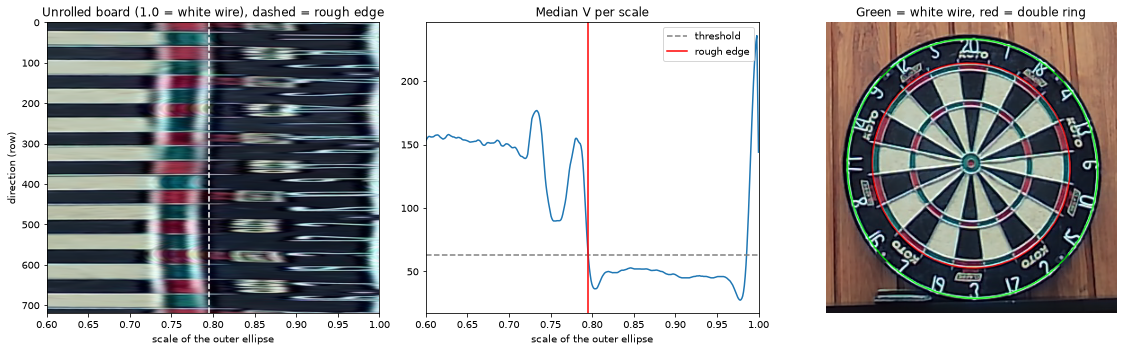

In [16]:
inner_ellipse, ratio, inner_inliers, details = find_inner_ellipse(clean, outer_ellipse, centre)
print(f"{inner_inliers.sum()} of {N_ANGLES} directions agree with the ellipse")
print(f"Inner ellipse is {ratio:.4f} x the outer ellipse")

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].imshow(cv2.cvtColor(details["unrolled"], cv2.COLOR_BGR2RGB), aspect="auto", extent=[0.3, 1, N_ANGLES, 0])
axs[0].axvline(details["rough_edge"], color="w", linestyle="--")
axs[0].set_xlim(0.6, 1)
axs[0].set_title("Unrolled board (1.0 = white wire), dashed = rough edge")
axs[0].set_xlabel("scale of the outer ellipse")
axs[0].set_ylabel("direction (row)")

axs[1].plot(details["scales"], details["brightness"])
axs[1].axhline(details["threshold"], color="gray", linestyle="--", label="threshold")
axs[1].axvline(details["rough_edge"], color="r", label="rough edge")
axs[1].set_xlim(0.6, 1)
axs[1].set_title("Median V per scale")
axs[1].set_xlabel("scale of the outer ellipse")
axs[1].legend()

result = clean.copy()
cv2.ellipse(result, outer_ellipse, (0, 255, 0), 1, cv2.LINE_AA)
cv2.ellipse(result, inner_ellipse, (0, 0, 255), 1, cv2.LINE_AA)
axs[2].imshow(cv2.cvtColor(crop_around(result, outer_ellipse[0], half_size), cv2.COLOR_BGR2RGB))
axs[2].set_title("Green = white wire, red = double ring")
axs[2].axis("off")
plt.tight_layout()
plt.show()

## **Step 6: The complete detector on all videos**

`detect_board` runs steps 2–5 on one image, and `calibrate_from_video` adds the median frame from step 1.

In [17]:
def detect_board(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    bullseye, _, _ = find_centre(image)
    outer_ellipse, _, outer_inliers = find_outer_ellipse(gray, bullseye)
    inner_ellipse, ratio, inner_inliers, _ = find_inner_ellipse(image, outer_ellipse, bullseye)

    return dict(
        bullseye=bullseye, outer=outer_ellipse, inner=inner_ellipse, ratio=ratio,
        outer_agreement=len(outer_inliers) / N_ANGLES,
        inner_agreement=inner_inliers.sum() / N_ANGLES,
    )


def draw_board(image, board):
    output = image.copy()
    cv2.ellipse(output, board["outer"], (0, 255, 0), 1, cv2.LINE_AA)
    cv2.ellipse(output, board["inner"], (0, 0, 255), 1, cv2.LINE_AA)
    return output


def calibrate_from_video(video_path):
    clean, frames = median_frame(video_path)
    start = time.perf_counter()
    board = detect_board(clean)
    board["seconds"] = time.perf_counter() - start
    board["image"] = clean
    return board

In [18]:
boards = {video.stem: calibrate_from_video(video) for video in videos}

print(f"{'video':32s} {'outer agree':>12s} {'inner agree':>12s} {'inner/outer':>12s} {'axis ratio':>11s} {'seconds':>8s}")
for name, b in boards.items():
    axes = b["outer"][1]
    print(f"{name:32s} {b['outer_agreement']:12.0%} {b['inner_agreement']:12.0%} {b['ratio']:12.4f} "
          f"{min(axes) / max(axes):11.3f} {b['seconds']:8.1f}")

video                             outer agree  inner agree  inner/outer  axis ratio  seconds
black_background_LightChange              91%          98%       0.7869       0.977      0.2
black_background_noHuman                  91%          98%       0.7870       0.981      0.2
black_background_yesHuman                 92%          98%       0.7869       0.978      0.3
white_background_LightChange              78%          96%       0.7854       0.938      0.2
white_background_noHuman                  83%          97%       0.7862       0.938      0.2
white_background_yesHuman                 83%          97%       0.7861       0.937      0.2
wood_background_Angle                     89%          97%       0.7909       0.860      0.3
wood_background_LightChange               89%          95%       0.7895       0.958      0.4
wood_background_noHuman                   89%          98%       0.7903       0.958      0.3
wood_background_yesHuman                  90%          98%       0.790

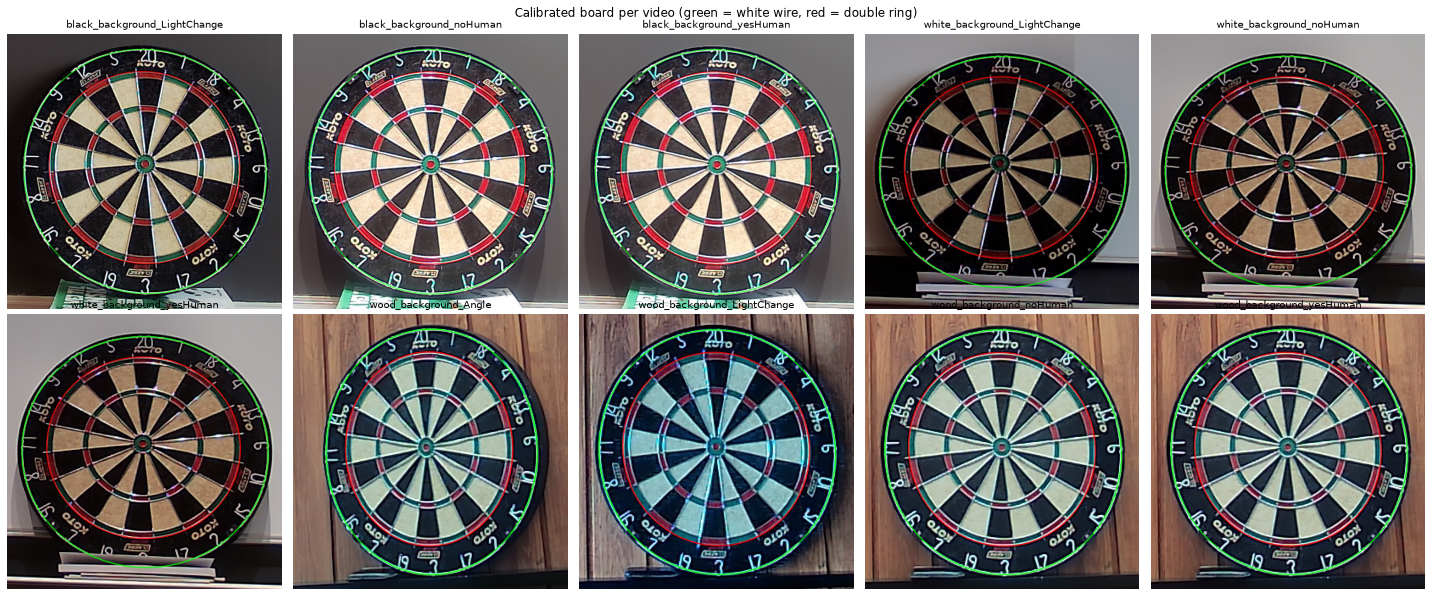

In [19]:
fig, axs = plt.subplots(2, 5, figsize=(20, 8.4))

for ax, (name, b) in zip(axs.ravel(), boards.items()):
    half_size = int(0.56 * max(b["outer"][1]))
    output = crop_around(draw_board(b["image"], b), b["outer"][0], half_size)
    ax.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    ax.set_title(name, fontsize=10)
    ax.axis("off")

plt.suptitle("Calibrated board per video (green = white wire, red = double ring)")
plt.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_DIR / "board_detection_all_videos.png", dpi=150)
plt.show()

### Zoom on the hardest case

The angled video at 3x zoom, on the left and right side of the board.

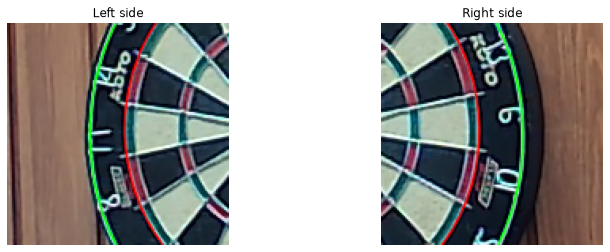

In [20]:
b = boards["wood_background_Angle"]
drawn = draw_board(b["image"], b)
(cx, cy), (width, height), _ = b["outer"]

left = crop_around(drawn, (cx - 0.42 * width, cy), 70)
right = crop_around(drawn, (cx + 0.42 * width, cy), 70)
zoom = lambda image: cv2.resize(image, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)
show([zoom(left), zoom(right)], ["Left side", "Right side"])

### Watch the result on a video (optional)

Opens a window that plays a video with the calibrated ellipses drawn on top. Press **q** to stop.
Set `PLAY_VIDEO = True` to run it.

In [21]:
PLAY_VIDEO = False
VIDEO_TO_PLAY = "wood_background_yesHuman"

if PLAY_VIDEO:
    board = boards[VIDEO_TO_PLAY]
    cap = cv2.VideoCapture(str(VIDEO_DIR / f"{VIDEO_TO_PLAY}.mp4"))

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        cv2.imshow("Board detector", cv2.resize(draw_board(frame, board), None, fx=0.5, fy=0.5))
        if cv2.waitKey(30) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()

## **Notes and limitations**

* **How we check the result without ground truth**
  * *Agreement*: the share of the 720 directions that lie within 2 px (outer) or 1.5 px (inner) of the final ellipse. High agreement means the ellipse really follows the wire and the ring all the way round.
  * *Inner/outer ratio*: all videos show the same physical board, so this ratio should be the same in every video, whatever the camera angle or background. It works as a test of accuracy, not just stability.
  * This is still not a true accuracy measure. For that we need hand-marked ground truth, which belongs in the evaluation part of the project.
* **Fixed sizes.** The structuring elements and search widths (11 px, 13 px, 8 px) are chosen for 1920 × 1080 with the board at about this size. They must be scaled when we test a lower resolution webcam.
* **Assumptions.** The board has a white wire circle outside the numbers and a dark number ring. This covers common boards, but not every board.
* **Calibration only.** The median frame needs an empty, still scene for a moment. A person standing in front of the board for most of the video would not be removed.
* **The tilt is taken from the outer ellipse.** Same shape is an approximation: under strong perspective two concentric circles give slightly different ellipse shapes. It fits very well at our angles, and the full perspective correction comes with the scoring step.